### Partially observable version of forecasting_ds

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import jax.random as jrandom
from sklearn.datasets import make_blobs, make_moons
from sklearn.preprocessing import MinMaxScaler
from dataclasses import dataclass
import jax
import jax.numpy as jnp
import flax.nnx as nnx
from functools import partial
from diffrax import ODETerm, Euler, Dopri5, AbstractSolver
import jax_dataloader as jdl
from tqdm import tqdm
import diffrax as dfx 
from dyn_plot import Plot 
import seaborn as sns
from typing import Tuple
import matplotlib.pyplot as plt
import numpy as np
from typing import List, Optional
import matplotlib.colors as mcolors
from matplotlib.figure import Figure
import optax

# automatic reloading of modules when they change
#from artcogsys.plotting import *

%reload_ext autoreload
%autoreload 2

key = jrandom.PRNGKey(0)


Hyperparameters. We can override this in the specific system descriptions

In [2]:
# hyperparameters. We can override this in the specific system descriptions

# data
num_timepoints = 100
t0=0
t1=20
ts = jnp.linspace(t0, t1, num_timepoints) # resolution of the trajectory
dt = (ts[-1] - ts[0]) / (len(ts) - 1)/5
history_size = int(num_timepoints/2.0)
n_train_test_samples=1024 # number of samples
batch_size=64

# model architecture
covariates_dim = 1
hidden_dim = 64
time_dim = 4
hidden_blocks = 3
rnn_hidden = 64
n_rnn_layers = 2

learning_rate = 3e-4

# flow prediction
n_samples=50  # number of samples to generate per trajectory
n_steps_flow=50 # number of steps to simulate the flow

# solver
solver = dfx.Tsit5()

# whether or not we are dealing with a stochastic system
stochastic = False


I will consider different systems as defined below

In [3]:
system = 'stochastic_harmonic_oscillator'

if system == 'lotka_volterra':
    def lotka_volterra(t, x, args):
        alpha, beta, gamma, delta = args[0]
        dx1 = alpha*x[0] - beta*x[0]*x[1]
        dx2 = -delta*x[1] + gamma*x[1]*x[0]
        return jnp.array([dx1, dx2])

    params = jnp.array([1.3, 0.9, 0.8, 1.8])

    vf = dfx.ODETerm(lotka_volterra) 

    data_dim = 2
    def initial_state(key, n_samples):
        return jrandom.uniform(key, (n_samples, data_dim), minval=0, maxval=5)

elif system == 'vanderpol':
    def vanderpol(t, x, args):
        mu, = args[0]
        dx1 = x[1]
        dx2 = mu*(1-x[0]**2)*x[1] - x[0]
        return jnp.array([dx1, dx2])

    params = jnp.array([1.0])

    vf = dfx.ODETerm(vanderpol)

     # data
    num_timepoints = 100
    t0=0
    t1=20
    ts = jnp.linspace(t0, t1, num_timepoints) # resolution of the trajectory
    dt = (ts[-1] - ts[0]) / (len(ts) - 1)/5
    history_size = int(num_timepoints/2.0)
    data_dim = 2
    initial_state = lambda key, n_samples: jrandom.uniform(key, (n_samples, data_dim), minval=-3, maxval=3)

elif system == 'lorenz':
    
    def lorenz(t, x, args):
        sigma, rho, beta = args[0]
        dx1 = sigma*(x[1] - x[0])
        dx2 = x[0]*(rho - x[2]) - x[1]
        dx3 = x[0]*x[1] - beta*x[2]
        return jnp.array([dx1, dx2, dx3])

    params = jnp.array([10.0, 28.0, 8/3])

    vf = dfx.ODETerm(lorenz)

    # data
    num_timepoints = 100
    t0, t1 = 0, 2
    ts = jnp.linspace(t0, t1, num_timepoints) # resolution of the trajectory
    dt = (ts[-1] - ts[0]) / (len(ts) - 1)/5
    history_size = int(num_timepoints/4)
    data_dim = 3

    if stochastic:

        initial_state = lambda key, n_samples: jnp.repeat(jnp.array((-6.557, -6.973, 24.059))[None, :], n_samples, axis=0)

        diffusion = lambda t, y, args: jnp.array((1.0, 1.0, 1.0))
        brownian_motion = dfx.VirtualBrownianTree(t0, t1, tol=1e-3, shape=(), key=jrandom.PRNGKey(0))
        cvf = dfx.ControlTerm(diffusion, brownian_motion)
        vf = dfx.MultiTerm(vf, cvf)

        solver = dfx.EulerHeun()

    else:
        initial_state = lambda key, n_samples: jrandom.uniform(key, (n_samples, data_dim), minval=0, maxval=10)

elif system == 'harmonic_oscillator':

    stochastic = False

    def harmonic_oscillator(t, x, args):
        gamma, omega = args[0]
        dx1 = x[1]
        dx2 = -gamma*x[1] - omega**2*x[0]
        return jnp.array([dx1, dx2])

    params = jnp.array([0.1, 1.0])

    vf = dfx.ODETerm(harmonic_oscillator)

    data_dim = 2
    initial_state = lambda key, n_samples: jrandom.uniform(key, (n_samples, data_dim), minval=-1, maxval=1) 

    learning_rate = 1e-5 # default seems too high

elif system == 'stochastic_harmonic_oscillator':

    stochastic = True

    def harmonic_oscillator(t, x, args):
        gamma, omega = args[0]
        dx1 = x[1]
        dx2 = -gamma*x[1] - omega**2*x[0]
        return jnp.array([dx1, dx2])

    params = jnp.array([0.1, 1.0])

    vf = dfx.ODETerm(harmonic_oscillator)

    data_dim = 2
    initial_state = lambda key, n_samples: jrandom.uniform(key, (n_samples, data_dim), minval=-1, maxval=1) 

    diffusion = lambda t, y, args: jnp.array((0.0, 1.0))
    brownian_motion = dfx.VirtualBrownianTree(t0, t1, tol=1e-3, shape=(), key=jrandom.PRNGKey(0))
    cvf = dfx.ControlTerm(diffusion, brownian_motion)
    vf = dfx.MultiTerm(vf, cvf)

    solver = dfx.EulerHeun()

    learning_rate = 1e-4 # default seems too high 

else:
    raise ValueError('System not implemented')

THIS IS WHERE WE CREATE PARTIAL OBSERVABILITY

In [4]:
output_dim = 4
noise_scale = 0.1
C = jrandom.normal(key, (output_dim, data_dim)) 
def observation_model(t, x, args):
    t_ = dfx._misc.force_bitcast_convert_type(t, jnp.int32)
    return C @ x + noise_scale * jrandom.normal(jrandom.fold_in(args[1], t_), shape=output_dim)

I generate both train and test data to prevent double dipping. Initial states are chosen uniformly random

In [5]:
## generate train and test trajectories

# NOTE: args now contains params and the key to generate unique observation noise
solve_single = lambda x0, key: dfx.diffeqsolve(vf, solver, ts[0], ts[-1], dt, x0, args=(params, key), saveat=dfx.SaveAt(ts=ts, fn=observation_model)).ys

for i in range(2):

    (key, ) = jrandom.split(key, 1)

    #sample initial conditions from a normal distribution 
    x0 = initial_state(key, n_train_test_samples)

    keys = jrandom.split(key, n_train_test_samples)
    trajectories = jax.vmap(solve_single)(x0, keys)

    # split trajectories to history and prediction 
    ts_history = ts[:history_size]
    ts_prediction = ts[history_size:]
    history = trajectories[:, :history_size, :]
    prediction = trajectories[:, history_size:, :]
    covariates = jnp.repeat(ts[None, :, None], n_train_test_samples, axis=0) # covariate is time index in this case

    if i==0:
        train_dataloader = jdl.DataLoader(jdl.ArrayDataset(history, covariates, prediction), 'jax', batch_size=batch_size, shuffle=True)
        train_trajectories = trajectories        
    else:
        test_dataloader = jdl.DataLoader(jdl.ArrayDataset(history, covariates, prediction), 'jax', batch_size=batch_size, shuffle=True)
        test_trajectories = trajectories


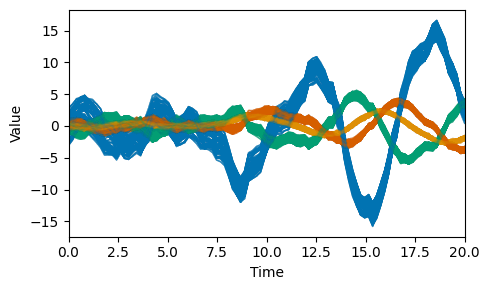

In [6]:
# with sns.axes_style("whitegrid", {'grid.linestyle': '--'}):

cmap = sns.color_palette('colorblind', n_colors=train_trajectories.shape[-1])

fig, ax = plt.subplots(1, 1, figsize=(5,3))
ax.margins(x=0)

for  idx, (history, covariates, prediction) in enumerate(train_dataloader):
    for i in range(len(history)):    
        for j in range(history.shape[-1]):
            ax.plot(ts, train_trajectories[i, :, j], linestyle='-', lw=1, alpha=0.1, color=cmap[j])
    
ax.set_xlabel('Time', color='#000000')
ax.set_ylabel('Value', color='#000000')

# plt.title(f'{system} training trajectories')
plt.tight_layout()

plt.savefig('figures/traindata_' + system + '_partial.pdf', dpi=300, bbox_inches='tight', format='pdf')

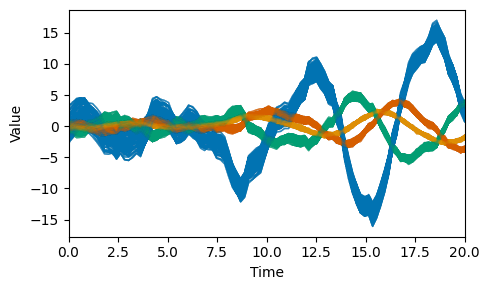

In [7]:
# with sns.axes_style("whitegrid", {'grid.linestyle': '--'}):

cmap = sns.color_palette('colorblind', n_colors=test_trajectories.shape[-1])

fig, ax = plt.subplots(1, 1, figsize=(5,3))
ax.margins(x=0)

for  idx, (history, covariates, prediction) in enumerate(test_dataloader):    
    for i in range(len(history)):
        for j in range(history.shape[-1]):
            ax.plot(ts, test_trajectories[i, :, j], linestyle='-', lw=1, alpha=0.1, color=cmap[j])

ax.set_xlabel('Time', color='#000000')
ax.set_ylabel('Value', color='#000000')

# plt.title(f'{system} test trajectories')
plt.tight_layout()

plt.savefig('figures/testdata_' + system + '_partial.pdf', dpi=300, bbox_inches='tight', format='pdf')

In [8]:
class ContextScaler:
    def fit_transform(self, context: jnp.ndarray) -> Tuple[jnp.ndarray, jnp.ndarray]:
        scale = jnp.mean(context, axis=0, keepdims=True) 
        scale = jnp.where(scale == 0, 1.0, scale)
        return context / scale, scale
    
    def transform(self, x: jnp.ndarray, scale: jnp.ndarray) -> jnp.ndarray:
        return x / scale
    
    
    def inverse_transform(self, x: jnp.ndarray, scale: jnp.ndarray) -> jnp.ndarray:
        return x * scale

@dataclass
class SinusodialPosEmb(nnx.Module):
    dim: int 
    def __call__(self, t):
        freqs = jnp.arange(1, self.dim//2 + 1) * jnp.pi
        emb = t * freqs
        return jnp.concatenate([jnp.sin(emb), jnp.cos(emb)], axis=-1)
    
class TimeConditionedDense(nnx.Module):
    def __init__(self, dim_x: int, dim_h: int, dim_t:int, rngs: nnx.Rngs):
        self.time_emb = SinusodialPosEmb(dim_t) 
        self.linear = nnx.Linear(dim_x + dim_h + dim_t , dim_x, rngs=rngs)
    
    def __call__(self, x, h, t):
        t = self.time_emb(t)
        x = jnp.concatenate([x, h, t], axis=-1) 
        return self.linear(x)


class Flow(nnx.Module):
    def __init__(self, dim_x: int, dim_c: int, dim_h: int, dim_t: int, dim_hidden: int, hidden_blocks: int, n_rnn_layers:int, rnn_hidden:int, rngs: nnx.Rngs):
        
        self.n_rnn_layers = n_rnn_layers
        self.rnn_hidden = rnn_hidden
        self.cells = [
            nnx.nn.recurrent.OptimizedLSTMCell(
                in_features=dim_x + dim_c if i == 0 else rnn_hidden,
                hidden_features=rnn_hidden,
                rngs=rngs
            ) for i in range(n_rnn_layers)
        ]
        self.dim_h = dim_h
        self.linear_in = nnx.Linear(dim_x + dim_h, dim_hidden, rngs=rngs)
        self.blocks = [TimeConditionedDense(dim_hidden, dim_h, dim_t, rngs) for _ in range(hidden_blocks)]
        self.linear_out = nnx.Linear(dim_hidden + dim_h, dim_x, rngs=rngs)

    @staticmethod
    def p0(key, shape):
        return jax.random.normal(key, shape) 

    def process_history(self,
                       x_history: jnp.ndarray,
                       c: jnp.ndarray) -> jnp.ndarray:
        """Process historical data through multiple LSTM layers."""
        inputs = jnp.concatenate([x_history, c[:x_history.shape[0]]], axis=-1)
        
        # Initialize carries for all layers
        carries = [(jnp.zeros((self.rnn_hidden)), jnp.zeros((self.rnn_hidden))) 
                  for _ in range(self.n_rnn_layers)]
        
        def scan_fn(carries: List[Tuple], x: jnp.ndarray) -> Tuple:
            current_input = x
            new_carries = []
            for i, (carry, cell) in enumerate(zip(carries, self.cells)):
                carry, output = cell(carry, current_input)
                current_input = output
                new_carries.append(carry)
            return new_carries, current_input

        final_carries, outputs = jax.lax.scan(scan_fn, carries, inputs)
        return outputs[-1]  # Return the last hidden state from the last timestep
    
    def __call__(self, z, x_history, c, t):
        h_last = self.process_history(x_history, c)
        z = nnx.gelu(self.linear_in(jnp.concatenate([z, h_last], axis=-1)))
        for block in self.blocks:
            z = nnx.gelu(block(z, h_last, t)) + z
        x_next = self.linear_out(jnp.concatenate([z, h_last], axis=-1))
        return x_next


In [9]:
# prediction model parameters
rngs = nnx.Rngs(0)

flow_model = Flow(output_dim, covariates_dim, hidden_dim, time_dim, hidden_dim, hidden_blocks, n_rnn_layers, rnn_hidden, rngs)

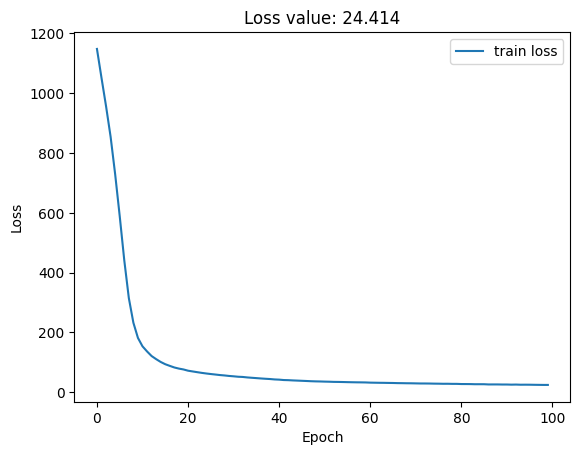

100%|██████████| 100/100 [3:52:29<00:00, 139.49s/it]   


In [10]:
def loss_fn(flow_model, history, covariates, prediction, rngs):
        
        x_past = history
        window_size = history.shape[1]
        loss = 0.0
        
        context_scaler = ContextScaler()

        for i in range(prediction.shape[1]):
            #x_past, scale = jax.vmap(context_scaler.fit_transform)(x_past)
            #prediction = jax.vmap(context_scaler.transform)(prediction, scale)
            x_next = prediction[:, i]
            t = jax.random.uniform(rngs(), (x_next.shape[0],), minval=0.0, maxval=1.0)
            x0 = flow_model.p0(rngs(), shape=x_next.shape)
            z = (1 - t[:, None]) * x0 + t[:, None] * x_next
            pred_flow = jax.vmap(flow_model)(z, x_past, covariates, t)
            optimal_flow = x_next - x0
            x_past = jnp.concatenate([x_past, x_next[:, None]], axis=1)
            x_past = x_past[:, -window_size:]
            loss += jnp.mean(jnp.square(pred_flow - optimal_flow))
        return loss
    
@nnx.jit
def train_step(model, optimizer, history, covariates, prediction, rngs):
    loss, grads = nnx.value_and_grad(loss_fn)(model, history, covariates, prediction, rngs)
    optimizer.update(grads)
    return loss

@nnx.jit
def test_step(model, optimizer, history, covariates, prediction, rngs):
    loss = loss_fn(model, history, covariates, prediction, rngs)
    return loss

# Initialize optimizer and RNG
optimizer = nnx.Optimizer(flow_model, optax.adam(learning_rate))

# Training loop
loss_plot = Plot()
losses = []
test_losses = []
rngs = nnx.Rngs(0)

for epoch in tqdm(range(100)):
    
    # optimize on training data
    epoch_loss = 0.0
    for batch_idx, (history, covariates, prediction) in enumerate(train_dataloader):
        loss = train_step(flow_model, optimizer, history, covariates, prediction, rngs)
        epoch_loss += loss

    avg_epoch_train_loss = epoch_loss / (batch_idx + 1)
    losses.append(float(avg_epoch_train_loss))

    # compute test loss
    epoch_loss = 0.0
    for batch_idx, (history, covariates, prediction) in enumerate(test_dataloader):
        loss = test_step(flow_model, optimizer, history, covariates, prediction, rngs)
        epoch_loss += loss

    avg_epoch_test_loss = epoch_loss / (batch_idx + 1)
    test_losses.append(float(avg_epoch_test_loss))
    
    with loss_plot:
        loss_plot.clear()
        loss_plot.plot(losses, label='train loss')
        loss_plot.set_title(f"Loss value: {avg_epoch_train_loss:.3f}")
        loss_plot.set_xlabel("Epoch")
        loss_plot.set_ylabel("Loss")
        loss_plot.legend()

loss_plot.close()


### Evaluation

In [11]:
def sample_flow(model, key, history, covariates, n_steps_flow, n_steps_pred, n_samples):
    
    def predict(key, history, covariates, n_steps_flow, n_steps_pred):
        def vf(t, x, args):
            history, covariates = args
            return model(x, history, covariates, t)
            
        term = ODETerm(vf)
        solver = dfx.Euler()
        dt = 1/n_steps_flow
        predictions = []
        current_history = history
        context_length = history.shape[0]
        context_scaler = ContextScaler()
        for _ in range(n_steps_pred):
            context = current_history[-context_length:]
            #context, scale = context_scaler.fit_transform(context)
            x0 = model.p0(key, shape=(history.shape[-1],))
            x_next = dfx.diffeqsolve(
                term, solver, 0., 1., dt, x0, 
                args=(context, covariates), 
                saveat=dfx.SaveAt(t1=True)
            ).ys
            #x_next = context_scaler.inverse_transform(x_next, scale)
            predictions.append(x_next)
            current_history = jnp.concatenate([current_history, x_next], axis=0)
            
        predictions = jnp.vstack(predictions)
        return predictions

    key_samples = jrandom.split(key, n_samples)
    
    # First vmap over batch, then over samples
    vmapped_predict = jax.vmap(predict, in_axes=(None, 0, 0, None, None))  # vmap over batch
    vmapped_predict = jax.vmap(vmapped_predict, in_axes=(0, None, None, None, None))  # vmap over samples
    
    pred_samples = vmapped_predict(key_samples, history, covariates, n_steps_flow, n_steps_pred)
    return pred_samples

In [12]:
# choose the first two trajectories in the test set (to maintain size consistency)
data = next(iter(test_dataloader))
data = tuple([d[:2] for d in data])

history, covariates, future = data
n_steps_pred=future.shape[1] # number of steps to predict

flow_predictions = sample_flow(flow_model, key, history, covariates, n_steps_flow, n_steps_pred, n_samples)
# print(flow_predictions.shape)

In [13]:
# # debug 
# traj = jnp.vstack([history[0], future[0]])
# plt.plot(traj);

IndexError: list index out of range

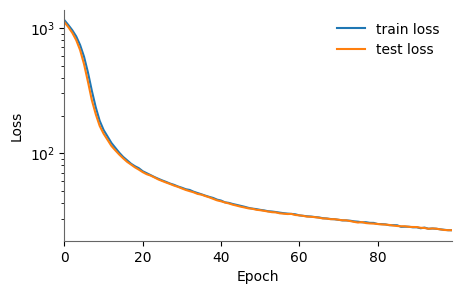

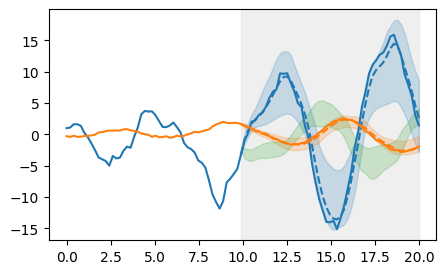

In [ ]:
def plot_trajectories(
        ts: np.ndarray,
        history: np.ndarray,  # Shape: (T_hist, C)
        predictions: np.ndarray,  # Shape: (N, T_pred, C)
        true_future: Optional[np.ndarray] = None,  # Shape: (T_pred, C)
        channel_names: Optional[List[str]] = None,
        title: str = "Trajectory Predictions",
        confidence_interval: float = 0.95,
        ax: Optional[plt.Axes] = None
    ) -> Figure:
        """
        Plot trajectory predictions with confidence intervals
        
        Args:
            ts: Time points
            history: Historical data with shape (T_hist, C) where C is number of channels
            predictions: MCMC predictions with shape (N, T_pred, C) where N is number of samples
            true_future: Optional ground truth future trajectory with shape (T_pred, C)
            channel_names: Optional list of channel names
            title: Plot title
            confidence_interval: Confidence interval for the prediction bounds (default: 0.95)
            ax: Optional matplotlib axis to plot on
            
        Returns:
            matplotlib.figure.Figure: The figure object containing the plot
        """
        if ax is None:
            fig = plt.figure(figsize=(12, 6))
            ax = plt.gca()
        
        # print(history.shape, predictions.shape, true_future.shape)

        # Get number of channels
        n_channels = history.shape[1]
        
        colors = list(mcolors.TABLEAU_COLORS)[:n_channels]
        colors_ = list(mcolors.TABLEAU_COLORS)[:n_channels]
        if channel_names is None:
            channel_names = [f'Channel {i+1}' for i in range(n_channels)]
        
        # Calculate prediction statistics
        pred_mean = np.mean(predictions, axis=0)  # Shape: (T_pred, C)
        lower_percentile = (1 - confidence_interval) / 2 * 100
        upper_percentile = (1 + confidence_interval) / 2 * 100
        pred_lower = np.percentile(predictions, lower_percentile, axis=0)
        pred_upper = np.percentile(predictions, upper_percentile, axis=0)
        
        # Get indices for the different regions
        history_end_idx = len(history) - 1
        pred_end_idx = history_end_idx + len(pred_mean)
        
        # Add background shading for history and prediction regions
        ax.axvspan(ts[0], ts[history_end_idx], color='#f0f0f0', alpha=0.0, zorder=1)
        ax.axvspan(ts[history_end_idx], ts[pred_end_idx], color='#e0e0e0', alpha=0.5, zorder=1)
                
        for i in range(n_channels):

            pred_ts = ts[history_end_idx:pred_end_idx+1]
            pred_line = np.concatenate([history[-1:, i], pred_mean[:, i]])

            # Plot confidence intervals (align with prediction mean)
            pred_lower_extended = np.concatenate([history[-1:, i], pred_lower[:, i]])
            pred_upper_extended = np.concatenate([history[-1:, i], pred_upper[:, i]])
            ax.fill_between(pred_ts,
                          pred_lower_extended,
                          pred_upper_extended,
                          color=colors[i],
                          alpha=0.2,
                          zorder=2,
                          label=f'{int(confidence_interval*100)}% CI')

            # Plot history line
            ax.plot(ts[:len(history)], history[:, i],
                   color=colors[i],
                   label=channel_names[i],
                   linewidth=1.5,
                   zorder=3)
            
            # Plot prediction mean (starting from the last history point)
            ax.plot(pred_ts, pred_line,
                   color=colors_[i],
                   label="forecast",
                   linewidth=1.5,
                   linestyle='--',  # Changed to dashed for predictions
                   zorder=3)
                        
            # Plot ground truth if available (starting from last history point)
            if true_future is not None:
                true_ts = ts[history_end_idx:history_end_idx+len(true_future)+1]
                true_line = np.concatenate([history[-1:, i], true_future[:, i]])
                ax.plot(true_ts,
                       true_line,
                       color=colors[i],
                       linestyle='-',  # Changed to solid for true future
                       linewidth=1.5,
                       zorder=3)
        
                # Add region labels
        y_range = ax.get_ylim()
        y_pos = y_range[1] - 0.05 * (y_range[1] - y_range[0])
        # ax.text(ts[history_end_idx//2], y_pos, 'History', 
        #         horizontalalignment='center', verticalalignment='top', fontsize=10, color='#666666')
        # ax.text(ts[history_end_idx + len(pred_mean)//2], y_pos, 'Prediction', 
        #         horizontalalignment='center', verticalalignment='top', fontsize=10, color='#666666')
        
        # Customize appearance
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_color('#666666')
        ax.spines['bottom'].set_color('#666666')
        
        # Add labels
        ax.set_xlabel('Time', color='#000000')
        ax.set_ylabel('Value', color='#000000')
        ax.set_title(title, pad=20)
        
        # Customize legend
        # legend = ax.legend(bbox_to_anchor=(1.02, 1),
        #                  loc='upper left',
        #                  frameon=False)
        
        # Adjust layout to prevent legend cutoff
        plt.subplots_adjust(right=0.85, top=0.85)  # Adjusted top margin for region labels
        
        ax.margins(x=0)

fig, ax = plt.subplots(figsize=(5, 3))
ax.semilogy(losses, label='loss')
ax.semilogy(test_losses, label='loss')
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss");
ax.margins(x=0)
ax.legend(['train loss', 'test loss'], frameon=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#666666')
ax.spines['bottom'].set_color('#666666')
plt.savefig('figures/loss_' + system + '.pdf', dpi=300, bbox_inches='tight', format='pdf')

fig, ax = plt.subplots(figsize=(5, 3))

# plot the predictions for the n_idx test trajectories
plot_trajectories(ts, history[0], flow_predictions[:,0], future[0], title='', channel_names=['$x_'+str(i+1)+'$' for i in range(output_dim)], confidence_interval=0.95, ax=ax)
# plot_trajectories(ts[:150], history[n_idx,:,:], flow_predictions[:,n_idx,:50,:], future[n_idx,:50,:], title='', channel_names=['$x_'+str(i+1)+'$' for i in range(data_dim)], confidence_interval=0.90, ax=ax[1])

plt.savefig('figures/predictions_' + system + '_partial.pdf', dpi=300, bbox_inches='tight', format='pdf')



In [ ]:
def phase_portrait(vector_field, xrange=(-1,1), yrange=(-1,1), args=None, ax=None, color=(0.8, 0.8, 0.8, 1.0)):
    """
    Plot phase portrait for a given vector field.

    Parameters:
    vector_field (callable): A function that takes three arguments (time, state, args) and returns a 2D vector.
    xrange (tuple, optional): The range of x values to plot. Default is (-1, 1).
    yrange (tuple, optional): The range of y values to plot. Default is (-1, 1).
    args (optional): Additional arguments to pass to the vector field function. Default is None.
    ax (matplotlib.axes.Axes, optional): Matplotlib Axes object to plot on. If None, a new figure and axes are created. Default is None.
    color (tuple, optional): The color of the streamlines. Default is (0.8, 0.8, 0.8, 1.0).

    Returns:
    matplotlib.axes.Axes: The axes object with the phase portrait plotted.
    """

    assert vector_field(0, jnp.zeros(2), args).size == 2, "Vector field should return a 2D vector."

    if ax is None:
        fig, ax = plt.subplots(ncols=1, figsize=(3, 3))

    # we are using arange since linspace can lead to uneven spacing!
    x_points = np.arange(xrange[0], xrange[1], (xrange[1]-xrange[0])/100)
    y_points = np.arange(yrange[0], yrange[1], (yrange[1]-yrange[0])/100)
    X, Y = np.meshgrid(x_points, y_points, sparse=False, indexing='xy')

    Z = jax.vmap(vector_field, in_axes=(None, 1, None))(0, jnp.vstack([X.flatten(), Y.flatten()]), args)

    U = jnp.reshape(Z[:,0], X.shape)
    V = jnp.reshape(Z[:,1], Y.shape)
    ax.streamplot(np.array(X), np.array(Y), np.array(U), np.array(V), density=0.8, color=color)

    return ax

def trajectories2d(xs, ax=None, marker=False, alpha=1.0, lw=1, palette='colorblind', color=None):
    """
    Plot trajectories in 2 dimensions

    Parameters:
        xs (Array): Trajectories to plot or list of trajectories [x1, x2, ...] or 3d array of shape (num_samples, num_timesteps, num_state_vars)
        ax (Matplotlib axes): If given, use these axis to plot on. Must be an array of length 3.
        marker: If given, plot the initial point of each trajectory with a marker.
        alpha: transparency
        lw: line width
        palette: color palette
    """

    if isinstance(xs, list):
        xs = jnp.array(xs)
    elif xs.ndim == 2:
        xs = xs[None, :, :]
        
    if ax is None:
        fig, ax = plt.subplots(1,1,figsize=(4,4))

    cmap = sns.color_palette(palette, n_colors=xs.shape[0])
    for i in range(len(xs)):
        if color is not None:
            ax.plot(xs[i,:,0], xs[i,:,1], alpha=alpha, lw=lw, color=color)
        else:
            ax.plot(xs[i,:,0], xs[i,:,1], alpha=alpha, lw=lw, color=cmap[i])
        if marker:
            ax.plot(xs[i,0,0], xs[i,0,1], marker='x', markersize=5, color='black')

    return ax

def trajectories3d(xs, ax=None, marker=False, alpha=1.0, lw=1, palette='colorblind', color=None):
    """
    Plot trajectories in 2 dimensions

    Parameters:
        xs (Array): Trajectories to plot or list of trajectories [x1, x2, ...] or 3d array of shape (num_samples, num_timesteps, num_state_vars) where num_state_vars = 3
        ax (Matplotlib axes): If given, use these axis to plot on. Must be an array of length 3.
        marker: If given, plot the initial point of each trajectory with a marker.
        alpha: transparency
        lw: line width
        palette: color palette
        color: color of the trajectories (overrides palette)
    """

    if isinstance(xs, list):
        xs = jnp.array(xs)
    elif xs.ndim == 2:
        xs = xs[None, :, :]
        
    if ax is None:
        fig, ax = plt.subplots(1,1,figsize=(5,5), subplot_kw=dict(projection='3d'))

    cmap = sns.color_palette(palette, n_colors=xs.shape[0])
    for i in range(len(xs)):
        if color is not None:
            ax.plot(xs[i,:,0], xs[i,:,1], xs[i,:,2], alpha=alpha, lw=lw, color=color)
        else:
            ax.plot(xs[i,:,0], xs[i,:,1], xs[i,:,2], alpha=alpha, lw=lw, color=cmap[i])
        if marker:
            ax.plot(xs[i,0,0], xs[i,0,1], xs[i,0,2], marker='x', markersize=5, color='black')

    return ax


In [ ]:

if data_dim == 2:

    ax = phase_portrait(vf.vector_field, xrange=(0, 9), yrange=(0, 9), args=params);
    # for idx, trajectory in enumerate(trajectories):
    #     plt.plot(trajectory[:, 0], trajectory[:, 1], 'b-', alpha=0.5)

    num_traj = 50
    trajectories_w_hist = jnp.hstack([jnp.repeat(history[0,-1,:][None, None, :], num_traj, axis=0), flow_predictions[:num_traj,0,:,:]])
    ax = trajectories2d(trajectories_w_hist, ax=ax, marker=None, alpha=0.1, lw=1.5, color='black');
    ax = trajectories2d(jnp.mean(trajectories_w_hist, axis=0), ax=ax, marker=None, alpha=1, lw=1.5, color='blue');

    # ax = trajectories2d(trajectories, ax=ax, marker=False, alpha=1.0, lw=1.0, palette='mako');
    # trajectories2d(trajectories[-1], ax=ax, marker=False, alpha=0.5, lw=0.5, palette='mako');

else:
    
    num_traj = 50
    trajectories_w_hist = jnp.hstack([jnp.repeat(history[0,-1,:][None, None, :], num_traj, axis=0), flow_predictions[:num_traj,0,:,:]])
    ax = trajectories3d(trajectories_w_hist, ax=None, marker=None, alpha=0.1, lw=1.5, color='black');
    ax = trajectories3d(jnp.mean(trajectories_w_hist, axis=0), ax=ax, marker=None, alpha=1, lw=1.5, color='blue');

    # plot ground truth
    gt_data = jnp.vstack([history[0,:,:], future[0,:,:]])[None, :, :]
    ax = trajectories3d(gt_data, ax=ax, marker=True, alpha=0.5, lw=1.5, palette=None, color='red');
    ax = trajectories3d(future[0,:,:], ax=ax, marker=False, alpha=0.5, lw=1.5, palette=None, color='red');
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    ax.set_zticklabels([])
    # ax.view_init(-37.5, 60, 180)

plt.savefig('figures/phasediagram_' + system + '_partial.pdf', dpi=300, bbox_inches='tight', format='pdf')

